# Q2: What 3P% breaks even, and does it change with volume?

A three is worth 3 points, so a three beats an average two-point attempt when

    3P% > (points per 2-point attempt) / 3

Shot-level data: every FGA, 2014-15 to 2025-26 (regular season + playoffs).

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.features import load_shots, load_team_games, breakeven_3p
plt.rcParams['figure.dpi'] = 110
s = load_shots()
s['IS3'] = (s.SHOT_TYPE == '3PT Field Goal')
s['PTS'] = s.SHOT_MADE_FLAG * np.where(s.IS3, 3, 2)
print(f'{len(s):,} shots')

2,695,400 shots


## 1. League break-even by season

,fg2,ppa2,fg3,breakeven_3p,edge_pts_per_3PA,share_3PA,ft_pts_per_fga
SEASON,,,,,,,
2014-15,0.485,0.969,0.350,0.323,0.080,0.270,0.206
2015-16,0.490,0.981,0.354,0.327,0.080,0.286,0.209
2016-17,0.504,1.008,0.358,0.336,0.066,0.318,0.210
2017-18,0.510,1.021,0.361,0.340,0.062,0.338,0.194
2018-19,0.519,1.037,0.354,0.346,0.026,0.360,0.200
2019-20,0.524,1.048,0.358,0.349,0.026,0.387,0.202
2020-21,0.530,1.060,0.366,0.353,0.039,0.392,0.193
2021-22,0.532,1.064,0.354,0.355,-0.003,0.400,0.193
2022-23,0.547,1.094,0.360,0.365,-0.013,0.388,0.208


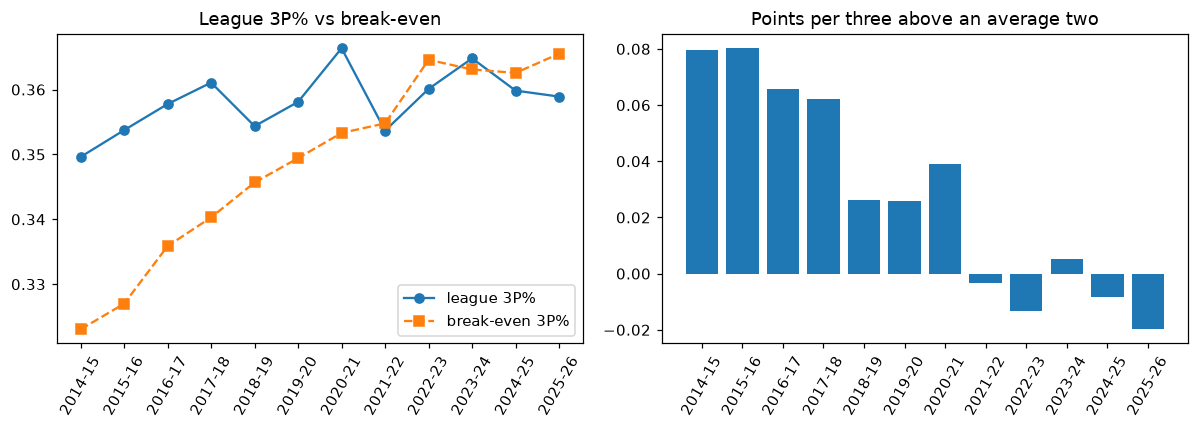

In [2]:
g = load_team_games()
ft = g.groupby('SEASON').agg(FTA=('FTA','sum'), FTM=('FTM','sum'), FGA=('FGA','sum'))
by = s.groupby('SEASON').apply(lambda d: pd.Series({
    'n2': (~d.IS3).sum(), 'ppa2': d.loc[~d.IS3, 'PTS'].mean(), 'fg2': d.loc[~d.IS3, 'SHOT_MADE_FLAG'].mean(),
    'n3': d.IS3.sum(), 'fg3': d.loc[d.IS3, 'SHOT_MADE_FLAG'].mean()}), include_groups=False)
by['breakeven_3p'] = breakeven_3p(by.ppa2)
by['edge_pts_per_3PA'] = 3*by.fg3 - by.ppa2          # points gained per three vs average two
by['share_3PA'] = by.n3/(by.n3+by.n2)
# Fuller measure: add free-throw points per FGA (all attempts, so a shot-neutral adjustment)
by['ft_pts_per_fga'] = ft.FTM/ft.FGA
display(by[['fg2','ppa2','fg3','breakeven_3p','edge_pts_per_3PA','share_3PA','ft_pts_per_fga']].round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(by.index, by.fg3, 'o-', label='league 3P%'); ax[0].plot(by.index, by.breakeven_3p, 's--', label='break-even 3P%')
ax[0].legend(); ax[0].tick_params(axis='x', rotation=60); ax[0].set_title('League 3P% vs break-even')
ax[1].bar(by.index, by.edge_pts_per_3PA); ax[1].tick_params(axis='x', rotation=60); ax[1].set_title('Points per three above an average two')
plt.tight_layout(); plt.show()

Free throws: a drawn foul on a two is worth extra points that a three rarely carries, so the pure shot-based break-even is the cleaner comparison; the free-throw column above is context only. Shot-level data does not tell us which attempts drew fouls (and-ones appear only as made shots).

## 2. Where the threes are taken: corner vs above the break

mean                   size       
zone    Above the break Corner Above the break Corner
SEASON                                               
2014-15           0.340  0.386           43426  15363
2015-16           0.349  0.378           46615  16408
2016-17           0.352  0.387           53482  16796
2017-18           0.355  0.395           58863  16711
2018-19           0.349  0.381           64392  19102
2019-20           0.351  0.389           59921  17820
2020-21           0.360  0.393           61303  18929
2021-22           0.346  0.383           68838  23034
2022-23           0.354  0.384           66890  22461
2023-24           0.359  0.388           67765  23577
2024-25           0.353  0.386           72620  25153
2025-26           0.349  0.386           71625  25146

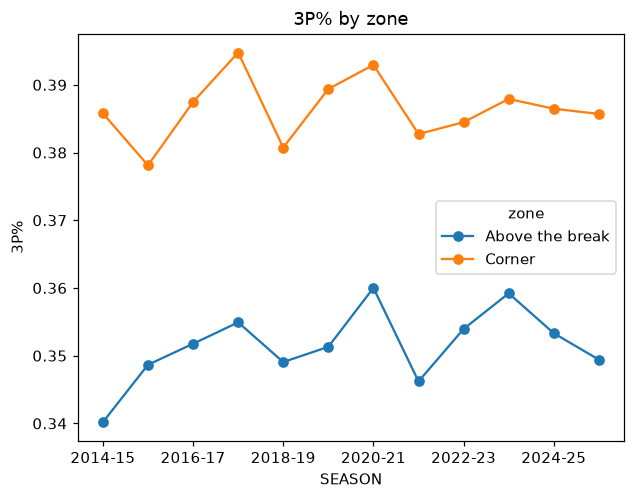

In [3]:
z = s[s.IS3 & s.SHOT_ZONE_BASIC.isin(['Left Corner 3','Right Corner 3','Above the Break 3'])].copy()
z['zone'] = np.where(z.SHOT_ZONE_BASIC == 'Above the Break 3', 'Above the break', 'Corner')
zt = z.groupby(['SEASON','zone']).SHOT_MADE_FLAG.agg(['mean','size']).unstack()
display(zt.round(3))
zt['mean'].plot(marker='o'); plt.ylabel('3P%'); plt.title('3P% by zone'); plt.show()

## 3. Does efficiency fall as shooter volume rises?

Player-season, minimum 100 3PA. Volume bucket = 3PA per team game the player's team played that season (a per-team-game rate, so players are comparable regardless of minutes).

In [4]:
tg = g.groupby(['SEASON','TEAM_ID']).size().rename('team_games').reset_index()
p = s[s.IS3].groupby(['SEASON','PLAYER_ID','PLAYER_NAME','TEAM_ID']).SHOT_MADE_FLAG.agg(fg3a='size', fg3m='sum').reset_index()
# players traded mid-season: combine across teams, use the larger team-game count
p = p.merge(tg, on=['SEASON','TEAM_ID'])
p = p.groupby(['SEASON','PLAYER_ID','PLAYER_NAME']).agg(fg3a=('fg3a','sum'), fg3m=('fg3m','sum'), team_games=('team_games','max')).reset_index()
p = p[p.fg3a >= 100].copy()
p['fg3_pct'] = p.fg3m/p.fg3a
p['rate'] = p.fg3a/p.team_games
p = p.merge(by[['breakeven_3p','ppa2']].reset_index(), on='SEASON')
p['bucket'] = pd.cut(p.rate, [0, 2, 3, 4, 5, 6, 20], labels=['<2','2-3','3-4','4-5','5-6','6+'])
bt = p.groupby('bucket', observed=True).apply(lambda d: pd.Series({
    'players': len(d), 'fg3a_total': d.fg3a.sum(), 'fg3_pct': d.fg3m.sum()/d.fg3a.sum(),
    'mean_breakeven': d.breakeven_3p.mean(),
    'pts_per_3PA': 3*d.fg3m.sum()/d.fg3a.sum(),
    'share_above_breakeven': (d.fg3_pct > d.breakeven_3p).mean()}), include_groups=False)
bt['edge'] = bt.pts_per_3PA - 3*bt.mean_breakeven
display(bt.round(3))

,players,fg3a_total,fg3_pct,mean_breakeven,pts_per_3PA,share_above_breakeven,edge
bucket,,,,,,,
<2,820.0,111245.0,0.340,0.349,1.020,0.405,-0.027
2-3,796.0,169473.0,0.352,0.349,1.055,0.494,0.006
3-4,598.0,179542.0,0.364,0.350,1.093,0.635,0.043
4-5,448.0,173687.0,0.370,0.351,1.109,0.701,0.056
5-6,239.0,112954.0,0.374,0.352,1.123,0.757,0.067
6+,230.0,146024.0,0.378,0.354,1.133,0.800,0.071


In [5]:
# Within-player check: does the same player shoot worse in seasons where he shoots more?
from statsmodels.formula.api import ols
pp = p.copy()
pp['pid'] = pp.PLAYER_ID.astype(str)
m = ols('fg3_pct ~ rate + C(pid) + C(SEASON)', data=pp[pp.groupby('PLAYER_ID').PLAYER_ID.transform('size') >= 2]).fit(
    cov_type='cluster', cov_kwds={'groups': pp[pp.groupby('PLAYER_ID').PLAYER_ID.transform('size') >= 2].PLAYER_ID})
print(f"within-player: +1 3PA per team game -> {m.params['rate']*100:+.2f} pts of 3P% (95% CI {m.conf_int().loc['rate',0]*100:+.2f} to {m.conf_int().loc['rate',1]*100:+.2f})")

within-player: +1 3PA per team game -> +0.64 pts of 3P% (95% CI +0.51 to +0.76)


## 4. Shooters against the break-even line (latest season and all seasons)

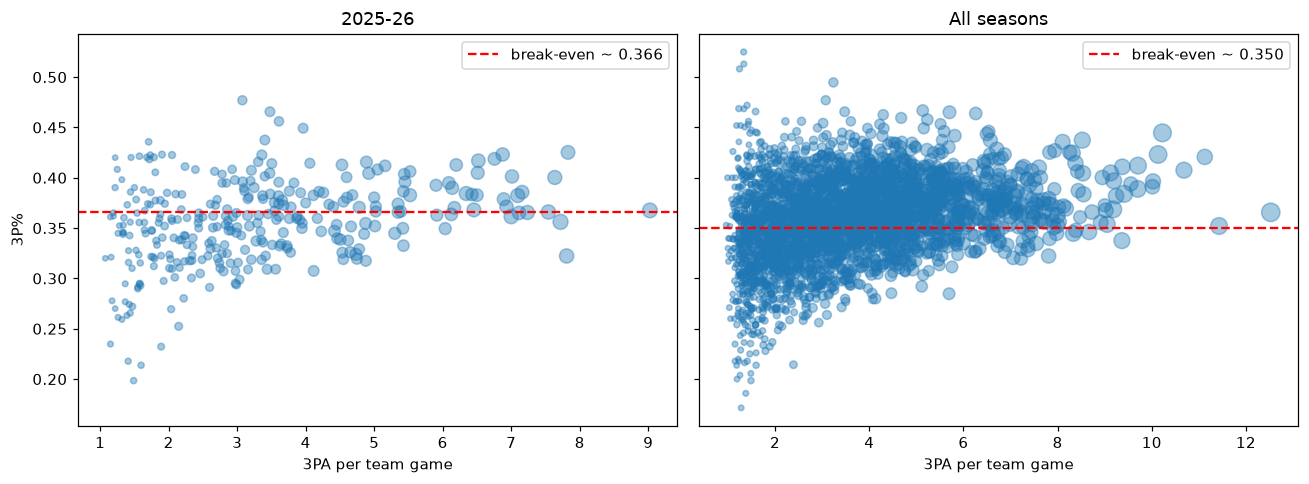

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for a, d, ttl in [(ax[0], p[p.SEASON == '2025-26'], '2025-26'), (ax[1], p, 'All seasons')]:
    a.scatter(d.rate, d.fg3_pct, s=d.fg3a/8, alpha=.4)
    be = d.breakeven_3p.mean(); a.axhline(be, c='r', ls='--', label=f'break-even ~ {be:.3f}')
    a.set_xlabel('3PA per team game'); a.set_title(ttl); a.legend()
ax[0].set_ylabel('3P%'); plt.tight_layout(); plt.show()

## Reading the results

- The break-even 3P% is about the same as league 3P% in most seasons, so the average three is only mildly better than the average two. This is the league-wide shot-selection picture: it assumes the shooter and shot location are typical.
- Efficiency vs volume is confounded by who gets to shoot (high-volume shooters are usually the best) and by shot difficulty. The within-player check is the cleaner read.
- Shot-quality context (open vs contested) is not in this data; zone and distance are the only quality proxies used.